# Standard Bayesian Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pymc as pm
import arviz as az

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import ARDRegression, BayesianRidge


import warnings
warnings.filterwarnings("ignore")

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Preprocessing & Visualization

In [3]:
carbon_footprint_df = pd.read_csv("/content/drive/MyDrive/personal_carbon_footprint/personal_carbon_footprint.csv").drop(columns = ['user_id', 'carbon_impact_level'], axis = 1)
carbon_footprint_df.head()

,day_type,transport_mode,distance_km,electricity_kwh,renewable_usage_pct,food_type,screen_time_hours,waste_generated_kg,eco_actions,carbon_footprint_kg
0,Weekend,EV,1.55,6.12,0,Non-Veg,2.4,0.70,1,11.03
1,Weekend,Walk,10.04,4.50,0,Mixed,4.1,0.54,1,7.44
2,Weekday,Walk,15.27,2.81,0,Mixed,4.0,0.51,1,6.01
3,Weekend,Walk,0.50,10.16,0,Mixed,6.3,0.73,0,12.70
4,Weekend,Walk,3.60,5.02,50,Mixed,5.1,0.64,0,6.33


In [4]:
carbon_footprint_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   day_type             1400 non-null   object 
 1   transport_mode       1400 non-null   object 
 2   distance_km          1400 non-null   float64
 3   electricity_kwh      1400 non-null   float64
 4   renewable_usage_pct  1400 non-null   int64  
 5   food_type            1400 non-null   object 
 6   screen_time_hours    1400 non-null   float64
 7   waste_generated_kg   1400 non-null   float64
 8   eco_actions          1400 non-null   int64  
 9   carbon_footprint_kg  1400 non-null   float64
dtypes: float64(5), int64(2), object(3)
memory usage: 109.5+ KB


In [5]:
def day_type_encoder(data):
  if data == 'Weekday':
    return 0
  else:
    return 1

carbon_footprint_df['day_type'] = carbon_footprint_df['day_type'].apply(day_type_encoder)

In [6]:
def food_type_encoder(data):
  if data == 'Non-Veg':
    return 0
  elif data == 'Mixed':
    return 1
  else:
    return 2

carbon_footprint_df['food_type'] = carbon_footprint_df['food_type'].apply(food_type_encoder)

In [7]:
carbon_footprint_df['transport_mode'].value_counts()

,count
transport_mode,
Bike,291
Walk,290
Bus,276
EV,272
Car,271


In [8]:
def transport_mode_encoder(data):
  if data == 'Bike':
    return 0
  elif data == 'Walk':
    return 1
  elif data == 'Bus':
    return 2
  elif data == 'EV':
    return 3
  elif data == 'Car':
    return 4

carbon_footprint_df['transport_mode'] = carbon_footprint_df['transport_mode'].apply(transport_mode_encoder)

In [9]:
carbon_footprint_df.head()

,day_type,transport_mode,distance_km,electricity_kwh,renewable_usage_pct,food_type,screen_time_hours,waste_generated_kg,eco_actions,carbon_footprint_kg
0,1,3,1.55,6.12,0,0,2.4,0.70,1,11.03
1,1,1,10.04,4.50,0,1,4.1,0.54,1,7.44
2,0,1,15.27,2.81,0,1,4.0,0.51,1,6.01
3,1,1,0.50,10.16,0,1,6.3,0.73,0,12.70
4,1,1,3.60,5.02,50,1,5.1,0.64,0,6.33


In [10]:
X_train, X_test, y_train, y_test = train_test_split(carbon_footprint_df.drop(columns = ['carbon_footprint_kg'], axis = 1),
                                                    carbon_footprint_df['carbon_footprint_kg'],
                                                    test_size = 0.2,
                                                    random_state = 42)

In [11]:
feature_names = X_train.drop(columns = ['day_type', 'food_type'], axis = 1).columns.to_list()
scaler = StandardScaler()
X_train[feature_names] = scaler.fit_transform(X_train[feature_names])
X_test[feature_names] = scaler.transform(X_test[feature_names])
X_train.head()

,day_type,transport_mode,distance_km,electricity_kwh,renewable_usage_pct,food_type,screen_time_hours,waste_generated_kg,eco_actions
1121,0,0.746972,2.234422,0.912878,0.601369,1,-0.603386,-1.825750,-0.125044
48,0,0.746972,0.066794,0.952885,1.419758,0,1.220815,1.175441,-0.125044
155,1,0.039780,-0.228695,-1.037490,-1.035407,0,1.664539,-0.239406,-1.118306
306,0,1.454165,1.641332,-0.377366,0.601369,1,0.234760,0.875322,-0.125044
1287,0,-1.374606,0.579680,-1.972667,-1.035407,2,0.678485,-0.625274,1.861478


## Bayesian Ridge Linear Regression

In [12]:
with pm.Model() as bayesian_model:

  intercept = pm.Normal("intercept", mu = 0, sigma = 10)

  beta = pm.Normal("beta", mu = 0, sigma = 10, shape = X_train.shape[1])

  sigma = pm.HalfNormal("sigma", sigma = 1)

  mu = intercept + pm.math.dot(X_train, beta)

  y_obs = pm.Normal("carbon_footprint", mu = mu, sigma = sigma, observed = y_train)

  trace = pm.sample(2000, tune = 1000, cores = 2, random_state = 42, return_inferencedata = True)

  pm.sample_posterior_predictive(trace, extend_inferencedata = True)


Output()

Output()

## Bayesian Model Summary

In [13]:
print(az.summary(trace, var_names = ['intercept', 'beta', 'sigma']))

            mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
intercept  9.654  0.044   9.572    9.735      0.001    0.001    3053.0   
beta[0]    0.070  0.055  -0.036    0.170      0.001    0.001    3289.0   
beta[1]    0.551  0.022   0.511    0.596      0.000    0.000    6211.0   
beta[2]    0.296  0.028   0.239    0.344      0.000    0.000    4320.0   
beta[3]    1.085  0.023   1.045    1.131      0.000    0.000    5505.0   
beta[4]   -1.507  0.022  -1.550   -1.466      0.000    0.000    5586.0   
beta[5]   -1.743  0.027  -1.792   -1.692      0.000    0.000    4531.0   
beta[6]   -0.008  0.023  -0.049    0.036      0.000    0.000    6651.0   
beta[7]    0.282  0.024   0.235    0.324      0.000    0.000    6665.0   
beta[8]   -0.393  0.023  -0.436   -0.351      0.000    0.000    6895.0   
sigma      0.747  0.016   0.717    0.777      0.000    0.000    6150.0   

           ess_tail  r_hat  
intercept    3355.0    1.0  
beta[0]      2827.0    1.0  
beta[1]      3142.0    1

## Posterior Distribution

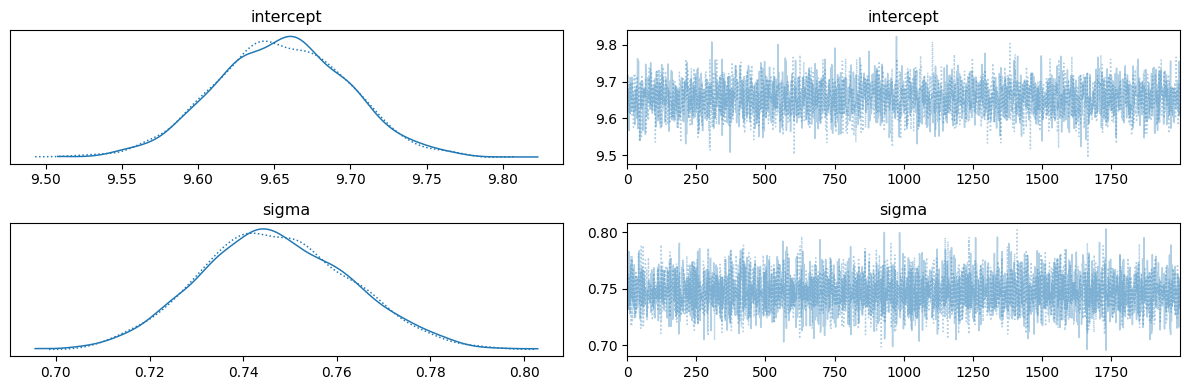

In [14]:
az.plot_trace(trace, var_names = ["intercept", "sigma"])
plt.tight_layout()
plt.show()

## Extract Posterior Mean Coefficients

In [15]:
beta_mean = trace.posterior["beta"].mean(dim=("chain", "draw")).values
beta_mean

array([ 0.07007129,  0.55127224,  0.2958121 ,  1.08489336, -1.5074521 ,
       -1.74322369, -0.0076585 ,  0.28179515, -0.39287894])

In [16]:
intercept_mean = trace.posterior["intercept"].mean(dim = ("chain", "draw")).values
intercept_mean

array(9.65438132)

In [17]:
for feature, coefficient in zip (X_train.columns, beta_mean):
  print("{} : {}".format(feature, coefficient))

day_type : 0.07007129323209893
transport_mode : 0.5512722362285528
distance_km : 0.29581209700317723
electricity_kwh : 1.0848933585086011
renewable_usage_pct : -1.5074520997311154
food_type : -1.743223688695901
screen_time_hours : -0.007658499239971458
waste_generated_kg : 0.2817951453287841
eco_actions : -0.3928789396998487


## Posterior Predictive Checks

In [18]:
posterior_pred = trace.posterior_predictive["carbon_footprint"]

hdi_95 = az.hdi(posterior_pred, hdi_prob = 0.95)
print("95% HDI Bounds: {}".format(hdi_95))
print()

eti_lower = posterior_pred.quantile(0.025, dim=["chain", "draw"])
eti_upper = posterior_pred.quantile(0.975, dim=["chain", "draw"])
print("95% ETI lower bound (first 5):", eti_lower[:5].values)
print("95% ETI upper bound (first 5):", eti_upper[:5].values)

95% HDI Bounds: <xarray.Dataset> Size: 27kB
Dimensions:                 (carbon_footprint_dim_0: 1120, hdi: 2)
Coordinates:
  * carbon_footprint_dim_0  (carbon_footprint_dim_0) int64 9kB 0 1 ... 1118 1119
  * hdi                     (hdi) <U6 48B 'lower' 'higher'
Data variables:
    carbon_footprint        (carbon_footprint_dim_0, hdi) float64 18kB 7.145 ...

95% ETI lower bound (first 5): [7.0749665  7.82911439 9.00864215 6.69912512 2.62639384]
95% ETI upper bound (first 5): [10.10095424 10.84868474 11.8995834   9.65451776  5.56335528]


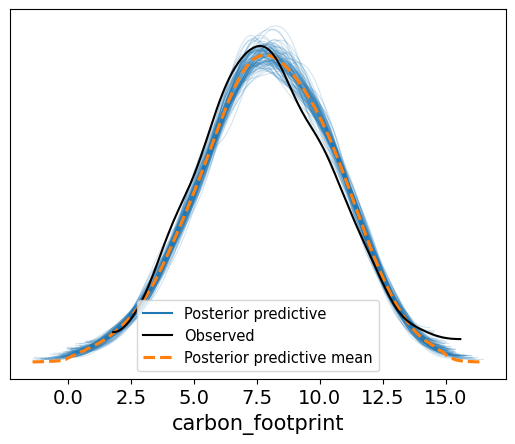

In [19]:
az.plot_ppc(trace, num_pp_samples=100)
plt.show()

## Make Predictions

In [20]:
y_pred_bayes = intercept_mean + np.dot(X_test, beta_mean)

## Model Evaluation



In [21]:
mae_bayes = mean_absolute_error(y_test, y_pred_bayes)
mse_bayes = mean_squared_error(y_test, y_pred_bayes)
rmse_bayes = np.sqrt(mse_bayes)
r2_bayes = r2_score(y_test, y_pred_bayes)

In [22]:
print("MAE: {:.4f}".format(mae_bayes))
print("MSE: {:.4f}".format(mse_bayes))
print("RMSE: {:.4f}".format(rmse_bayes))
print("R2: {:.4f}".format(r2_bayes))

MAE: 0.5930
MSE: 0.5805
RMSE: 0.7619
R2: 0.9231
